# EXPERIMENT NO: 7

## IMPLEMENTATION OF A SIMPLE AUTOENCODER FOR DIMENSIONALITY REDUCTION AND FEATURE LEARNING

**Name:** Ajaikumar M  
**Roll No:** 24BAD005  
**Course:** Deep Learning

**Part A – Dataset Preparation**


Import libraries and load MNIST

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from tensorflow.keras.datasets import mnist

# Load MNIST dataset
(x_train, _), (x_test, _) = mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Data type:", x_train.dtype)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Data type: uint8


Normalize the images

In [2]:
# Normalize pixel values from 0-255 to 0-1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


Flatten the images

In [3]:
x_train_flat = x_train.reshape(-1, 784)
x_test_flat = x_test.reshape(-1, 784)

print("Original image shape:", x_train.shape[1:])
print("Flattened training shape:", x_train_flat.shape)
print("Flattened testing shape:", x_test_flat.shape)

Original image shape: (28, 28)
Flattened training shape: (60000, 784)
Flattened testing shape: (10000, 784)


Display sample images

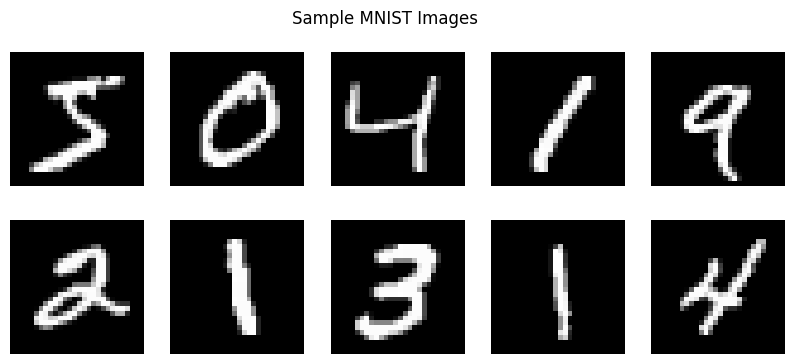

In [4]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.axis("off")

plt.suptitle("Sample MNIST Images")
plt.show()

**Part B — Implementing the Autoencoder**

Build the Encoder

In [5]:
from tensorflow.keras import layers, Model

# Input layer
input_layer = layers.Input(shape=(784,))

# Encoder
encoded = layers.Dense(128, activation="relu")(input_layer)

# Bottleneck / latent representation
latent = layers.Dense(32, activation="relu", name="bottleneck")(encoded)

# Decoder
decoded = layers.Dense(128, activation="relu")(latent)
output_layer = layers.Dense(784, activation="sigmoid")(decoded)

# Complete Autoencoder
autoencoder = Model(input_layer, output_layer)

# Separate Encoder
encoder = Model(input_layer, latent)

# Compile model
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

Display model architecture

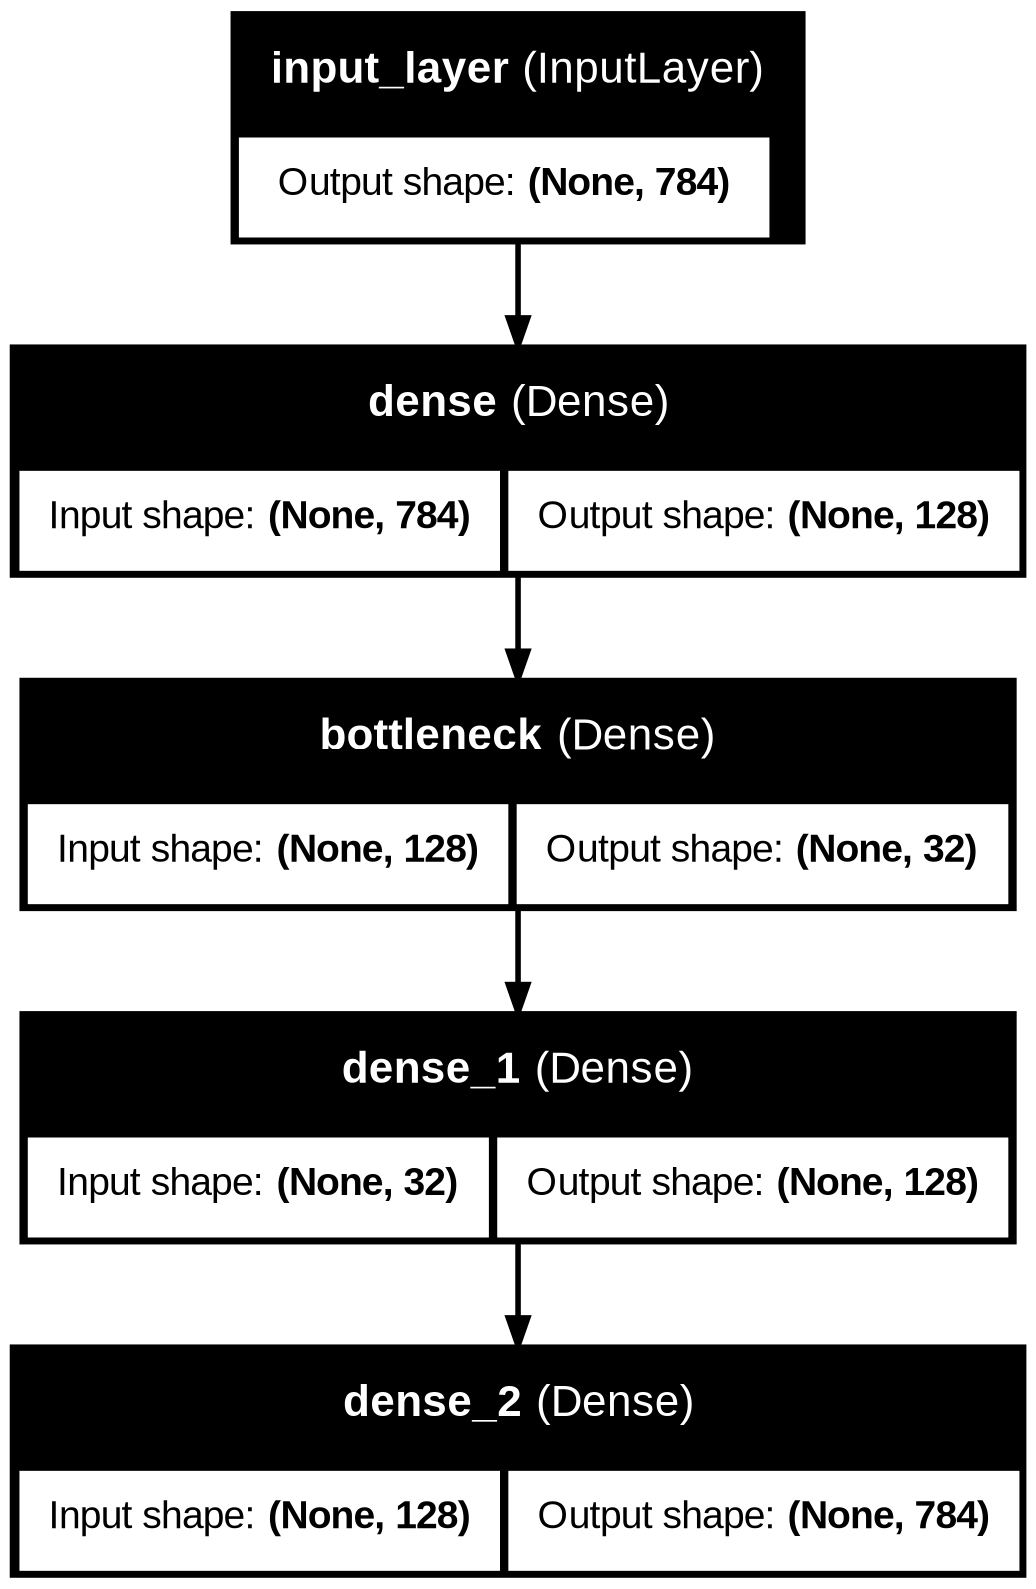

In [6]:
from tensorflow.keras.utils import plot_model

plot_model(
    autoencoder,
    to_file="autoencoder_architecture.png",
    show_shapes=True,
    show_layer_names=True
)

from IPython.display import Image
display(Image(filename="autoencoder_architecture.png"))

Check the compressed representation

In [7]:
# Generate latent representations for some test images
latent_features = encoder.predict(x_test_flat[:10])

print("Original dimensions:", x_test_flat[:10].shape)
print("Compressed dimensions:", latent_features.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step
Original dimensions: (10, 784)
Compressed dimensions: (10, 32)


**Part C — Model Training and Performance Evaluation**

Train the Autoencoder

In [8]:
history = autoencoder.fit(
    x_train_flat,
    x_train_flat,
    epochs=10,
    batch_size=256,
    validation_data=(x_test_flat, x_test_flat),
    verbose=1
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - loss: 0.0584 - val_loss: 0.0315
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0255 - val_loss: 0.0205
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0189 - val_loss: 0.0167
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0160 - val_loss: 0.0144
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0141 - val_loss: 0.0131
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0129 - val_loss: 0.0120
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0121 - val_loss: 0.0114
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0116 - val_loss: 0.0112
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0112 - val_loss: 0.0109
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0109 - val_loss: 0.0105


Display final training and validation loss

In [9]:
print("Final Training Loss:", history.history["loss"][-1])
print("Final Validation Loss:", history.history["val_loss"][-1])

Final Training Loss: 0.010941893793642521
Final Validation Loss: 0.010500757023692131


Plot Training vs Validation Loss

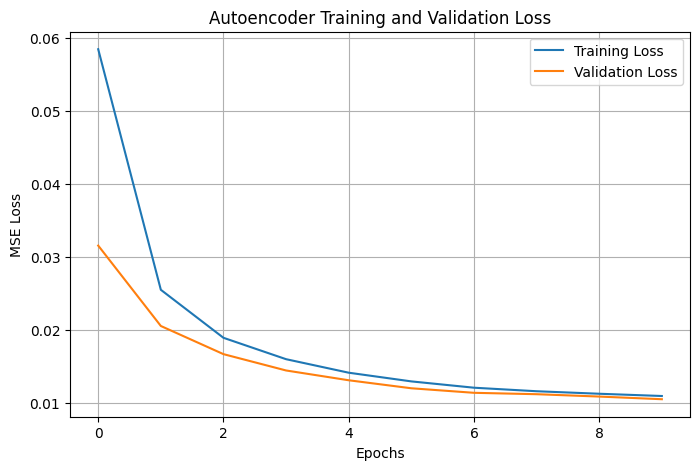

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

Evaluate the Autoencoder

In [11]:
test_loss = autoencoder.evaluate(
    x_test_flat,
    x_test_flat,
    verbose=0
)

print("Test Reconstruction MSE:", test_loss)

Test Reconstruction MSE: 0.010500757023692131


Reconstruct test images

In [12]:
reconstructed = autoencoder.predict(x_test_flat[:10])

print("Original shape:", x_test_flat[:10].shape)
print("Reconstructed shape:", reconstructed.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 264ms/step
Original shape: (10, 784)
Reconstructed shape: (10, 784)


Compare Original vs Reconstructed Images

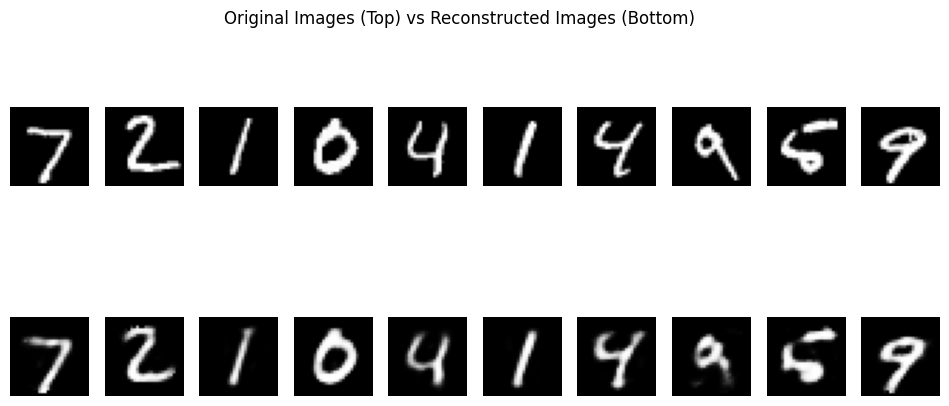

In [13]:
plt.figure(figsize=(12, 5))

for i in range(10):
    # Original
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test_flat[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

    # Reconstructed
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.suptitle("Original Images (Top) vs Reconstructed Images (Bottom)")
plt.show()

**Part D — Dimensionality Reduction and Feature Visualization**

Extract latent representations

In [14]:
# Extract compressed representations
latent_test = encoder.predict(x_test_flat)

print("Original test data shape:", x_test_flat.shape)
print("Latent representation shape:", latent_test.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Original test data shape: (10000, 784)
Latent representation shape: (10000, 32)


Visualize the latent representations

In [15]:
from sklearn.decomposition import PCA

# Use a subset for visualization
latent_sample = latent_test[:2000]

# Reduce 32 dimensions to 2 dimensions
pca = PCA(n_components=2)
latent_2d = pca.fit_transform(latent_sample)

print("Latent representation:", latent_sample.shape)
print("2D representation:", latent_2d.shape)

Latent representation: (2000, 32)
2D representation: (2000, 2)


Plot latent features

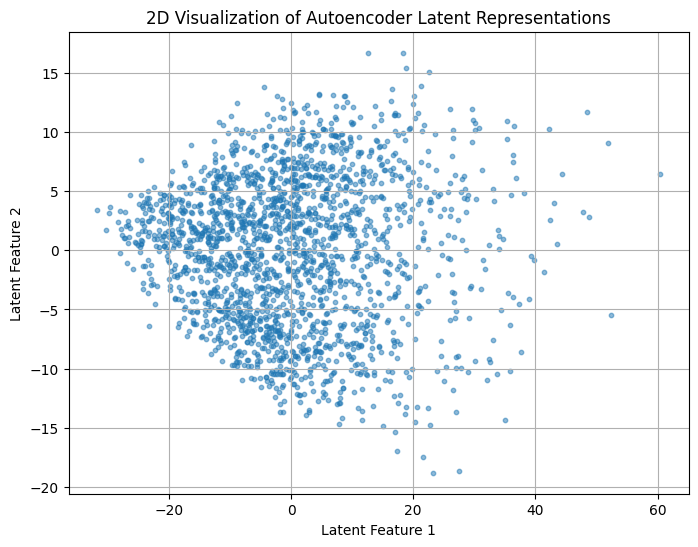

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    s=10,
    alpha=0.5
)

plt.xlabel("Latent Feature 1")
plt.ylabel("Latent Feature 2")
plt.title("2D Visualization of Autoencoder Latent Representations")
plt.grid(True)

plt.show()

Reconstruct selected test samples

In [17]:
# Select 10 test images
sample_images = x_test_flat[:10]

# Encode the images
encoded_images = encoder.predict(sample_images)

# Decode the latent representations
decoded_images = autoencoder.predict(sample_images)

print("Original shape:", sample_images.shape)
print("Encoded shape:", encoded_images.shape)
print("Decoded shape:", decoded_images.shape)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
Original shape: (10, 784)
Encoded shape: (10, 32)
Decoded shape: (10, 784)


Final comparison

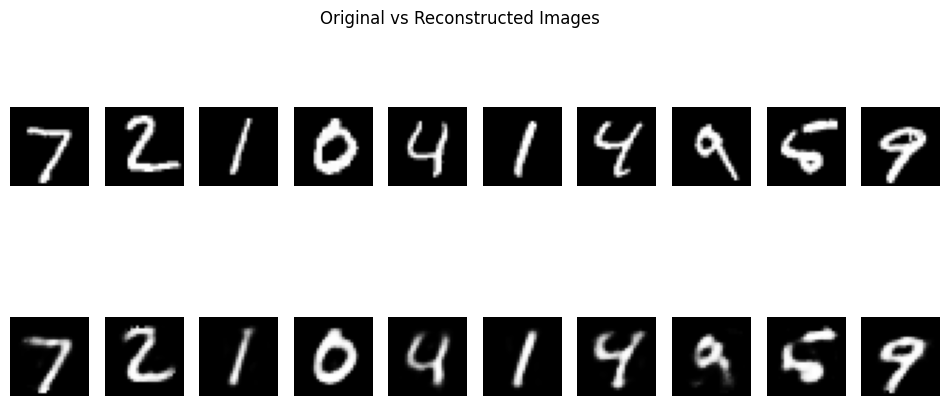

In [18]:
plt.figure(figsize=(12, 5))

for i in range(10):

    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(sample_images[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(decoded_images[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.suptitle("Original vs Reconstructed Images")
plt.show()